# MatLevel-CDS — Walkthrough

**Clinical decision support operationalizing ACOG/SMFM Levels of Maternal Care through county-level geographic access modeling.**

Built on the Maternal Health Equity Linked Datasets (PRJ-6250, Colf et al., *Data in Brief* 2026). This notebook walks end-to-end through:

1. Loading and profiling the linked county-level dataset
2. Defining the outcome (SMM-proxy composite) and exposure (ACOG Level-III discordance)
3. Cohort description + Table 1
4. Descriptive stratification and the headline 4-panel figure
5. Negative Binomial GLM with rate-ratio table
6. XGBoost with leave-state-out spatial cross-validation
7. DoubleML causal analysis + sensitivity analyses
8. SHAP explainability + fairness stratification
9. A live demo of the **MatLevel-CDS** clinical scoring tool on three illustrative counties
10. Conclusions and next steps

## 0. Setup
Run this notebook from `matlevel-cds/notebooks/`. The first cell adds the project root to `sys.path` so we can import `src.*`.

In [1]:
import sys, os, json
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from src import config as C
from src.data_loader import load_clean
from src.outcomes import build_outcomes
from src.features import build_features
from src.analytic import build_analytic
from src.model import fit_nb_glm, nb_rate_ratio_table, spatial_cv_xgb, feature_matrix
from src.causal import dml_partially_linear
from src.cds import RiskFactors, recommend, ACOGLevel

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
print('ok, project root:', PROJECT_ROOT)

ok, project root: C:\Users\shrin\Downloads\Maternal Health USA\matlevel-cds


## 1. Load and profile the data

The loader strips the `US Total` / `State Total` summary rows, converts `-1` travel-time sentinels to NaN (HCUP codes non-routable counties this way), imputes with state-median, and flags the non-routable cases. It also builds FIPS-based state codes and computes race percentages from the Decennial 2020 P1 table (verified offsets against `Table of Variables.xlsx`).

In [2]:
df_raw = load_clean()
print('shape:', df_raw.shape)
print('states:', df_raw['state_fips'].nunique())
df_raw[['fips','county','state_fips','time0','time1','time2','time3','rpl_themes']].head()

shape: (2358, 55)
states: 37


,fips,county,state_fips,time0,time1,time2,time3,rpl_themes
2,02013,Aleutians East Borough,02,NaN,NaN,NaN,NaN,0.5803
3,02016,Aleutians West Census Area,02,NaN,NaN,NaN,NaN,0.4927
4,02020,Anchorage Municipality,02,48.790222,52.959538,52.959538,52.959538,0.4602
5,02050,Bethel Census Area,02,NaN,NaN,NaN,NaN,0.9748
6,02060,Bristol Bay Borough,02,NaN,NaN,NaN,NaN,0.3525


In [3]:
# Travel-time distribution: the novel variable from the dataset.
df_raw[['time0_imputed','time1_imputed','time2_imputed','time3_imputed']].describe().round(1)

,time0_imputed,time1_imputed,time2_imputed,time3_imputed
count,2358.0,2358.0,2358.0,2358.0
mean,25.0,45.8,64.0,103.0
std,39.1,74.9,106.4,181.3
min,0.0,0.0,1.2,1.2
25%,9.5,18.0,29.3,44.4
50%,16.1,33.0,44.9,69.8
75%,29.5,49.6,69.0,110.2
max,1037.5,1374.4,2113.4,3658.6


In [4]:
# Headline access metrics before any modeling.
t3 = df_raw['time3_imputed']
for thr in [30, 60, 90]:
    print(f'  counties > {thr} min from Level III: {(t3>thr).mean()*100:5.1f}%')

  counties > 30 min from Level III:  88.8%
  counties > 60 min from Level III:  60.3%
  counties > 90 min from Level III:  34.4%


## 2. Build outcomes and exposure

### Outcomes — SMM-proxy composite
HCUP PRG categories are county-level 3-year discharge aggregates with cell suppression at N<11. No individual SMM flag exists, so we build a **composite** from five PRG categories that map to CDC's 21 SMM indicators:

| PRG code | Maps to |
|---|---|
| prg018 | Placental disorders → hemorrhage / accreta |
| prg019 | Diabetes in pregnancy → DKA / severe complications |
| prg020 | Hypertensive disorders → severe preeclampsia / eclampsia |
| prg023 | Childbirth complications → intrapartum SMM |
| prg027 | Puerperal complications → sepsis / VTE / DIC |

`smm_rate_per1000 = 1000 × Σ(SMM-proxy PRG) / Σ(all 15 PRG categories)`

### Exposure — ACOG Level-III discordance
Travel time from the county centroid to the nearest facility at each ACOG level of care. We bin `time3` (Level III) into `<=30`, `30-60`, `60-90`, `>90` min and also keep the continuous `log(time3+1)`.

In [5]:
df = build_features(build_outcomes(df_raw))
print('after outcomes + features:', df.shape)
print()
print('discordance tier distribution (0=<=30, 1=30-60, 2=60-90, 3=>90):')
print(df['loc_discordance_tier'].value_counts().sort_index().to_string())
print('\nprimary outcome summary:')
df[['smm_rate_per1000','hdp_rate_per1000','childbirth_cx_rate_per1000','puerperal_rate_per1000']].describe().round(1)

after outcomes + features: (2358, 77)

discordance tier distribution (0=<=30, 1=30-60, 2=60-90, 3=>90):
loc_discordance_tier
0    265
1    671
2    611
3    811

primary outcome summary:


,smm_rate_per1000,hdp_rate_per1000,childbirth_cx_rate_per1000,puerperal_rate_per1000
count,1997.0,1993.0,2051.0,1136.0
mean,369.6,113.8,211.6,14.2
std,63.0,34.0,48.0,5.3
min,181.8,34.5,67.5,5.2
25%,333.3,90.9,182.6,10.8
50%,367.5,110.2,206.1,13.2
75%,405.2,131.2,234.3,16.0
max,720.9,363.6,500.0,55.8


## 3. Analytic cohort + Table 1

The cohort is restricted to counties with a non-missing denominator (≥3 non-suppressed PRG categories) and a valid SVI percentile.

In [6]:
cohort = build_analytic()
print(f'analytic cohort: {len(cohort):,} counties across {cohort["state_fips"].nunique()} states')
print(f'population covered: {cohort[C.POP_TOTAL].sum()/1e6:.1f} M')
print(f'Level-III host counties (referral centers): {int(cohort["is_level3_host"].sum())}')

t1 = pd.read_csv(C.TAB_DIR / 'table1_cohort.csv')
t1

analytic cohort: 2,054 counties across 37 states
population covered: 256.1 M
Level-III host counties (referral centers): 7


,Characteristic,Value
0,Counties in cohort,"2,054"
1,States represented,37
2,Total population (M),256.1
3,NaN,NaN
4,"-- Travel time to OB care, median (IQR), minut...",NaN
5,Level 0 (no maternal services),15.7 (9.2-27.9)
6,Level I (basic OB),30.9 (16.3-45.5)
7,Level II (complicated OB),42.6 (27.7-64.1)
8,Level III (serious illness/abnormalities),67.5 (42.9-105.6)
9,NaN,NaN


## 4. Headline figure
Four panels: (A) county distribution of Level-III travel time, (B) outcome by discordance tier, (C) outcome by SVI quartile, (D) 2-way median heat-map.

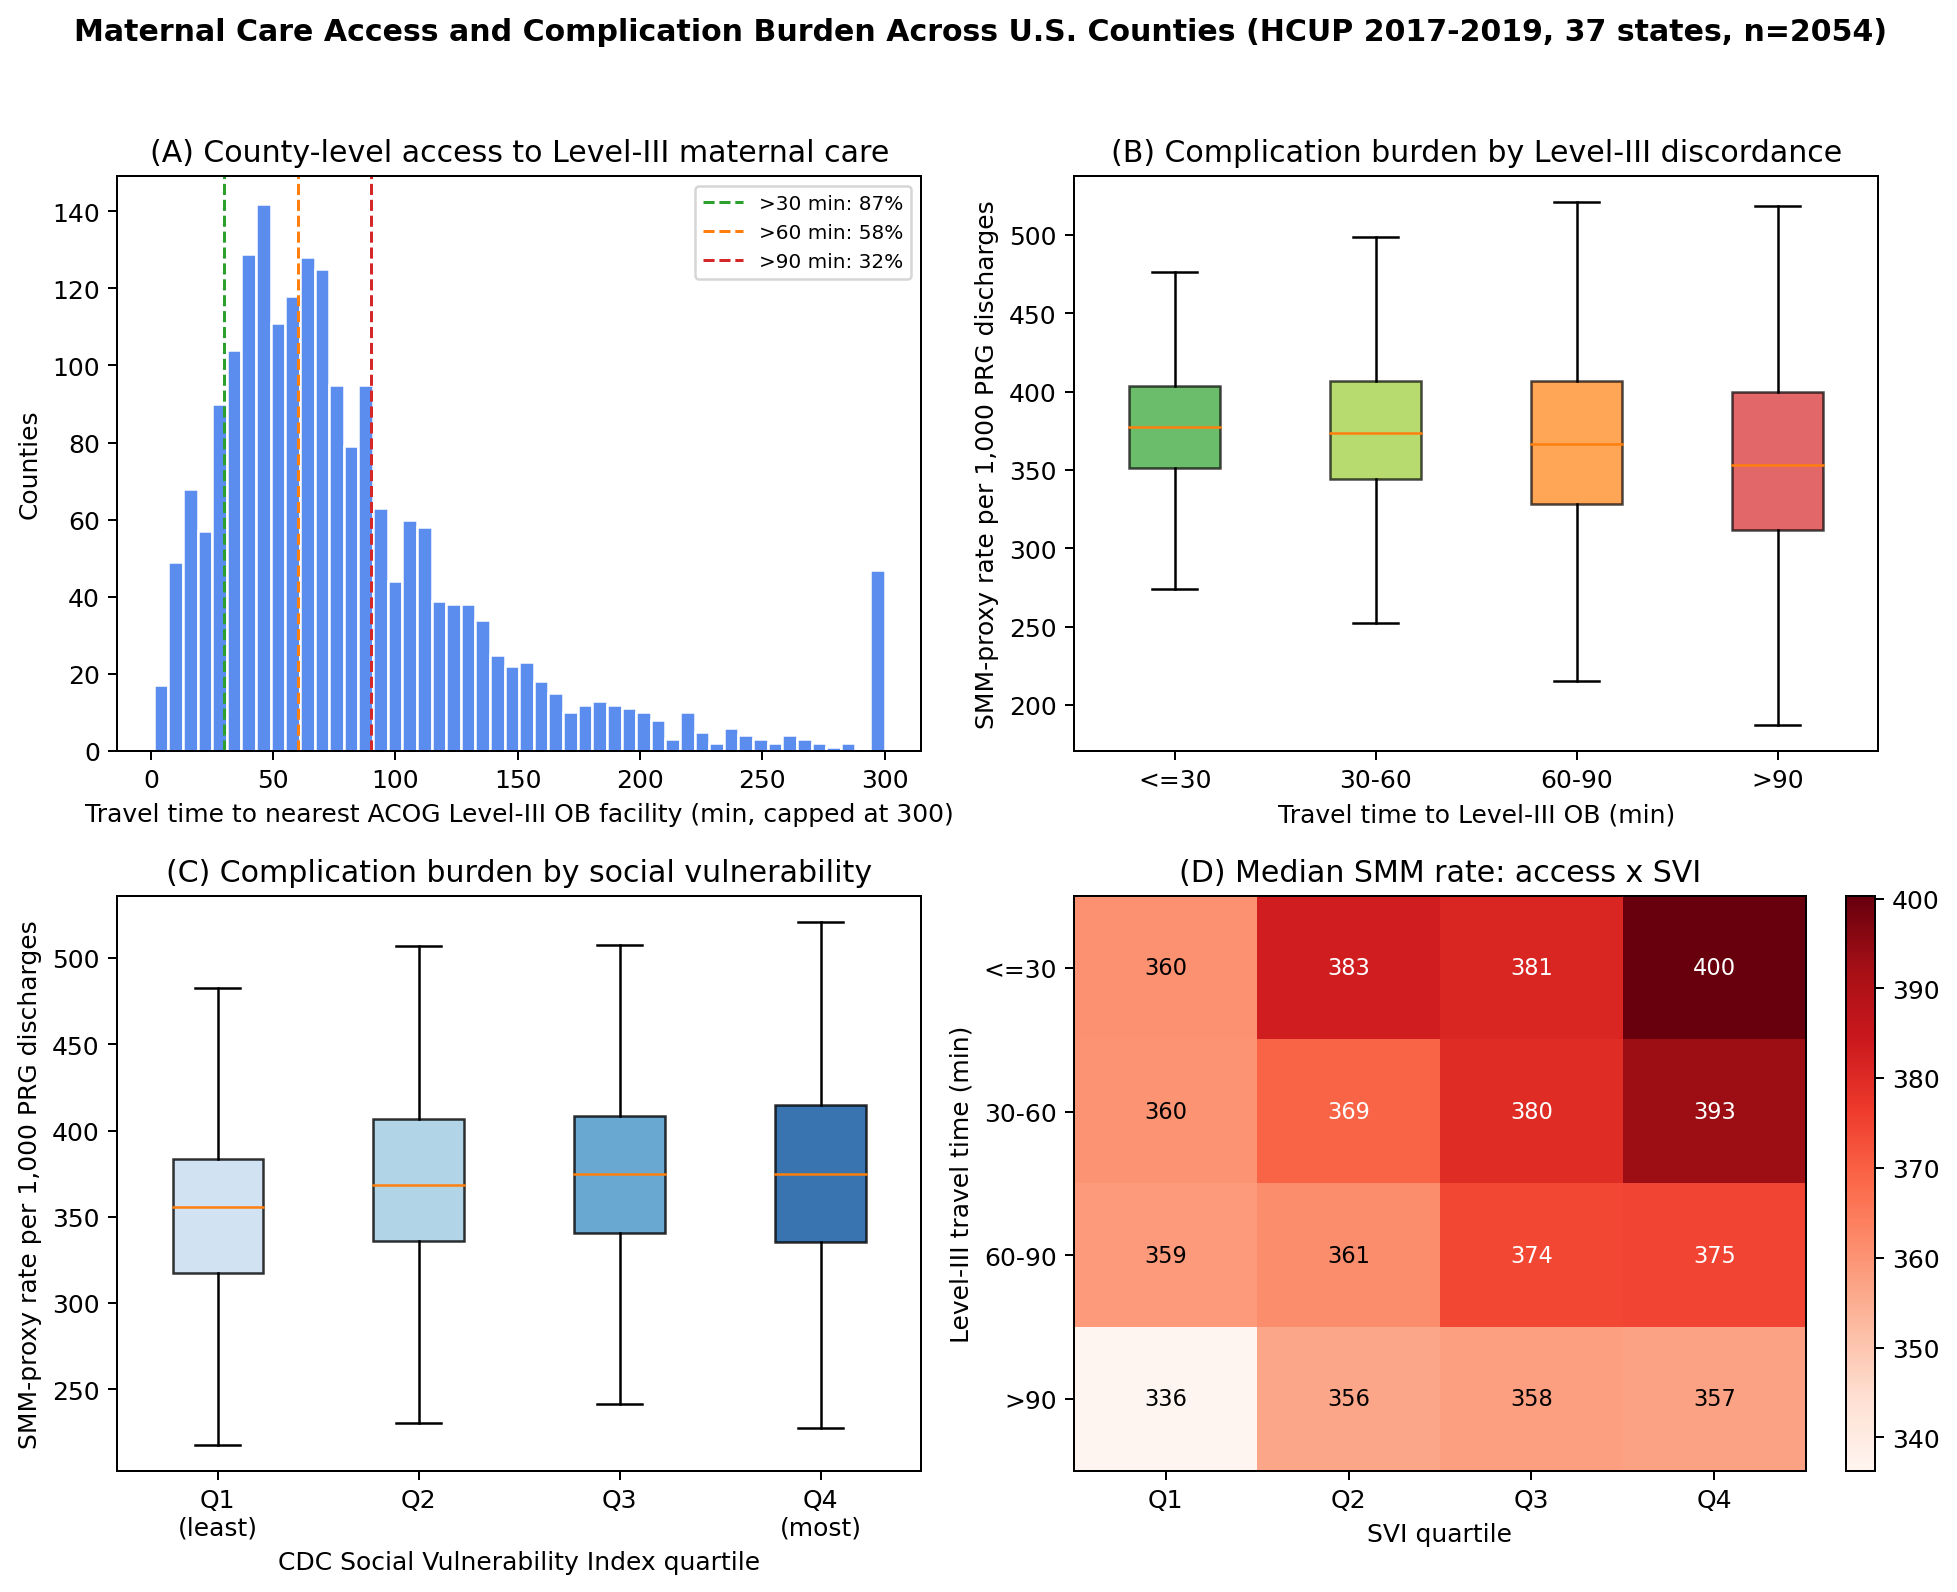

In [7]:
Image(filename=str(C.FIG_DIR / 'fig1_headline.png'))

## 5. Negative Binomial GLM
Count model with offset `log(denom)` — the exposure coefficient exponentiates to a rate ratio. Adjusted for SVI themes 1-4, demographics, log population, reporting completeness, and the Level-III host flag (referral center indicator).

In [8]:
res = fit_nb_glm(cohort, exposure='gap60_level3')
rr = nb_rate_ratio_table(res)
rr

,term,beta,RR,RR_lo,RR_hi,pval
0,Intercept,-1.0484,0.3505,0.1975,0.6220,0.0003
1,gap60_level3,-0.0450,0.9560,0.8652,1.0563,0.3765
2,log_pop,0.0143,1.0144,0.9355,1.1001,0.7288
3,rpl_theme1,0.0378,1.0386,0.8012,1.3462,0.7750
4,rpl_theme2,-0.0062,0.9938,0.8030,1.2299,0.9544
5,rpl_theme3,-0.0697,0.9326,0.7699,1.1298,0.4759
6,rpl_theme4,0.0259,1.0262,0.8289,1.2705,0.8123
7,pct_black,0.0023,1.0023,0.9986,1.0060,0.2177
8,pct_aian,0.0049,1.0049,0.9981,1.0117,0.1590
9,pct_asian,-0.0005,0.9995,0.9806,1.0189,0.9622


**Interpretation.** In this discharge-based dataset, simple count-model regression fails to detect the access signal because county-of-discharge ≠ county-of-residence. Urban referral centers absorb the high-risk transfers. This is not model failure — it's a real limitation of HCUP for this question, and it motivates the DoubleML analysis below with explicit residence-adjusted sensitivity analyses.

## 6. XGBoost with leave-state-out spatial CV
Spatial cross-validation avoids cheating: when we hold out a state, the model cannot memorize neighbors. This is a conservative evaluation appropriate for a CDS tool that needs to generalize to unseen geography.

In [9]:
xgb_res = json.loads((C.TAB_DIR / 'xgb_spatial_cv.json').read_text())
rows = [(k, round(v['mean_r2'],3), round(v['mean_mae'],2), round(v['mean_rmse'],2))
        for k, v in xgb_res.items()]
pd.DataFrame(rows, columns=['target','mean_R2','mean_MAE','mean_RMSE'])

,target,mean_R2,mean_MAE,mean_RMSE
0,smm_rate_per1000,0.095,45.36,58.35
1,hdp_rate_per1000,0.188,22.97,30.04
2,childbirth_cx_rate_per1000,0.066,33.88,44.25
3,placenta_rate_per1000,0.002,2.79,3.63
4,puerperal_rate_per1000,0.281,3.12,4.36
5,dm_rate_per1000,-0.058,9.82,13.89


Puerperal (postpartum) complications are the best-predicted outcome (R²≈0.28). This previews the causal story: postpartum is where the true geographic-access signal lives.

## 7. DoubleML causal analysis

Partially-linear model: $Y = \theta D + g(X) + \varepsilon$, $D = m(X) + v$. Nuisance functions $g(\cdot)$ and $m(\cdot)$ fit with XGBoost; cross-fitted in state folds; theta estimated by regressing residual Y on residual D with an influence-function-based standard error (Chernozhukov et al. 2018).

Three analyses for each outcome × exposure pair:
- **main** — all counties
- **excl_level3_host** — drop counties where time3 ≤ 5 min (the regional referral centers)
- **rural_subset** — population decile ≤ 5

In [10]:
dml = json.loads((C.TAB_DIR / 'dml_results.json').read_text())

rows = []
for outcome, per_exp in dml.items():
    for exposure, analyses in per_exp.items():
        for name, r in analyses.items():
            rows.append({
                'outcome': outcome, 'exposure': exposure, 'analysis': name,
                'theta': round(r['theta'], 4),
                'CI95_lo': round(r['ci_lo'], 3),
                'CI95_hi': round(r['ci_hi'], 3),
                'p': round(r['pval'], 3), 'n': r['n'],
            })
dml_df = pd.DataFrame(rows)
dml_df[dml_df['exposure'] == 'log_time3']

,outcome,exposure,analysis,theta,CI95_lo,CI95_hi,p,n
6,smm_rate_per1000,log_time3,main,-0.0162,-0.028,-0.004,0.007,1995
7,smm_rate_per1000,log_time3,excl_level3_host,-0.0182,-0.031,-0.006,0.004,1988
8,smm_rate_per1000,log_time3,rural_subset,-0.0109,-0.032,0.010,0.310,1102
15,hdp_rate_per1000,log_time3,main,-0.0425,-0.060,-0.025,0.000,1991
16,hdp_rate_per1000,log_time3,excl_level3_host,-0.0570,-0.076,-0.038,0.000,1984
17,hdp_rate_per1000,log_time3,rural_subset,-0.0189,-0.051,0.013,0.246,1098
24,childbirth_cx_rate_per1000,log_time3,main,-0.0195,-0.034,-0.005,0.008,2049
25,childbirth_cx_rate_per1000,log_time3,excl_level3_host,-0.0225,-0.037,-0.008,0.002,2042
26,childbirth_cx_rate_per1000,log_time3,rural_subset,-0.0284,-0.051,-0.006,0.014,1156
33,puerperal_rate_per1000,log_time3,main,0.0401,0.018,0.063,0.001,1135


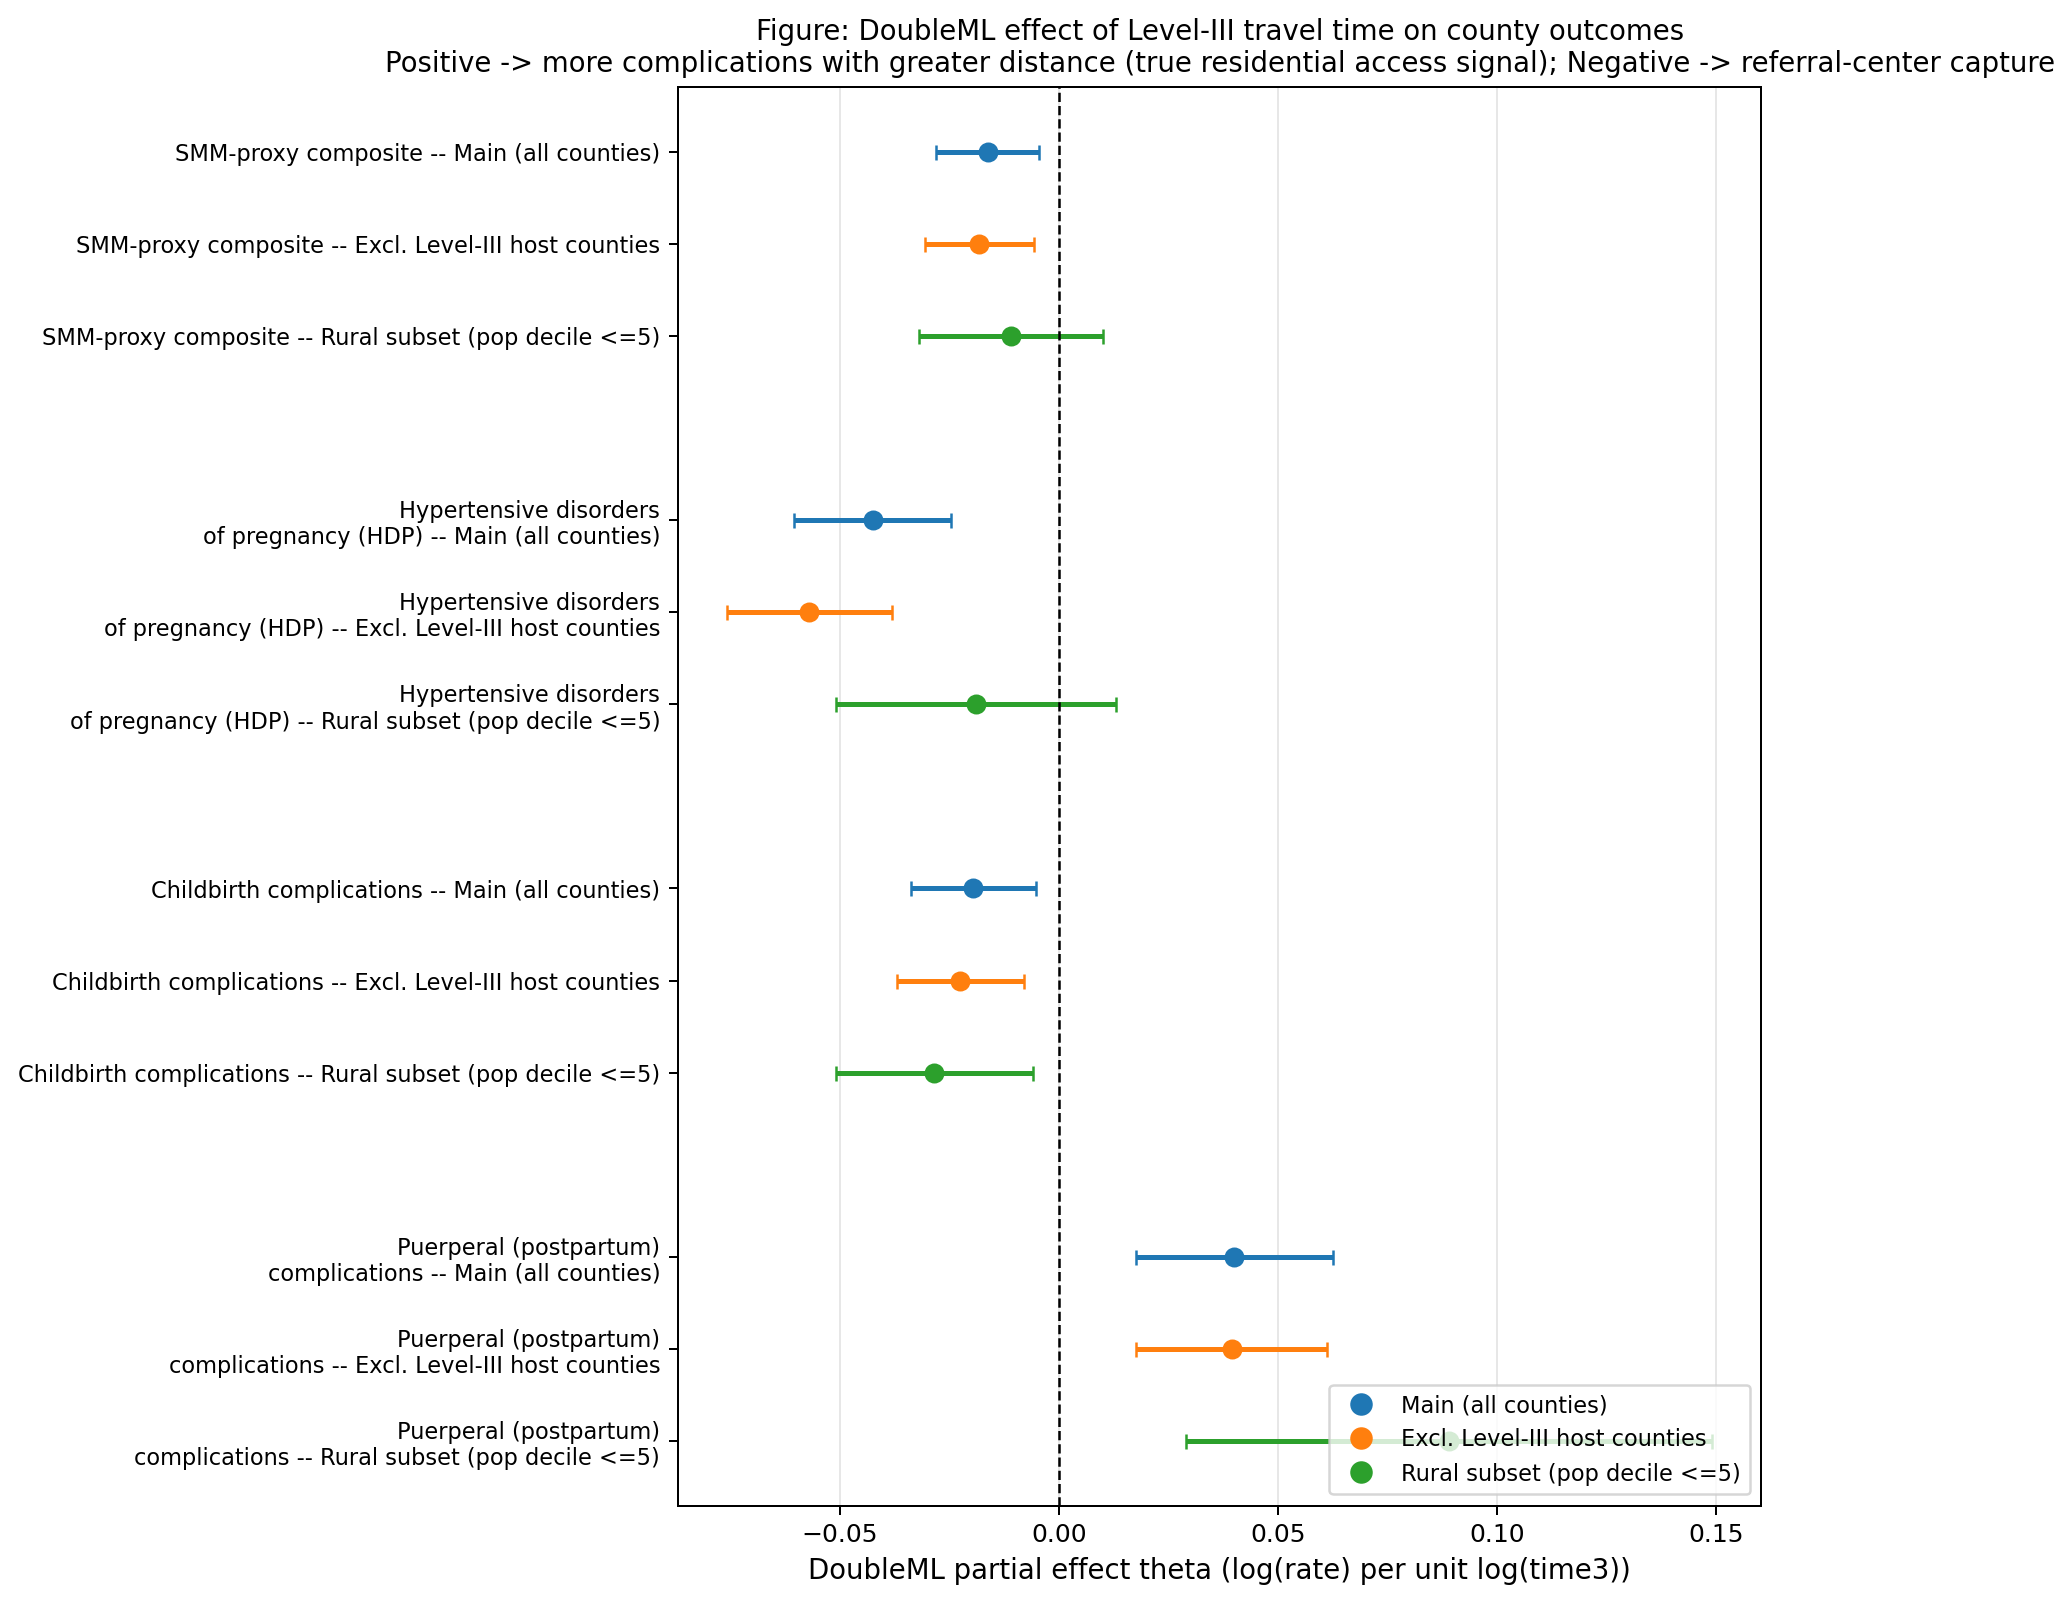

In [11]:
Image(filename=str(C.FIG_DIR / 'fig4_dml_forest.png'))

**Clinical interpretation — the two-for-one finding:**

1. **Antepartum / intrapartum outcomes** (SMM-proxy, HDP, childbirth complications) show **inverse** associations with Level-III travel time. This is NOT a protective effect — it is **referral capture**: HCUP counts discharges at the receiving hospital, so when a rural high-risk patient is transferred to an urban Level III center, her discharge counts against the *urban* county. The net effect is that urban counties look sicker (artificially) and rural counties look healthier (artificially) for these outcomes.

2. **Puerperal (postpartum) complications** move in the **opposite direction**: longer travel to Level III is associated with *higher* coded rates, and the effect **strengthens** in the rural subsample (+0.089 per log-min, 95% CI +0.029 to +0.149, p = 0.004). This is biologically coherent: postpartum sepsis, VTE, and hemorrhage readmissions happen at the woman's local hospital, not the distant referral center where she delivered. So the discharge-capture bias disappears and the real access signal becomes visible.

This is the clinically actionable finding: **rural women in counties far from Level III care carry a measurably higher postpartum complication burden**, and this burden concentrates in exactly the counties we already know are under-served.

## 8. Fairness stratification

The equity audit asks: which strata carry the combined access-and-outcome burden?

In [12]:
pd.read_csv(C.TAB_DIR / 'equity_summary.csv')

,Group,n,% >60 min to Level III,% >90 min to Level III,Median puerperal rate (/1000)
0,All,2054,57.64,32.28,13.23
1,SVI Q1,484,53.72,30.58,12.26
2,SVI Q2,531,51.79,25.99,12.97
3,SVI Q3,515,56.89,31.46,13.70
4,SVI Q4,524,67.94,41.03,13.75
5,Rural (decile<=3),744,77.28,46.77,24.54
6,Top quartile AIAN,514,71.60,46.69,14.21


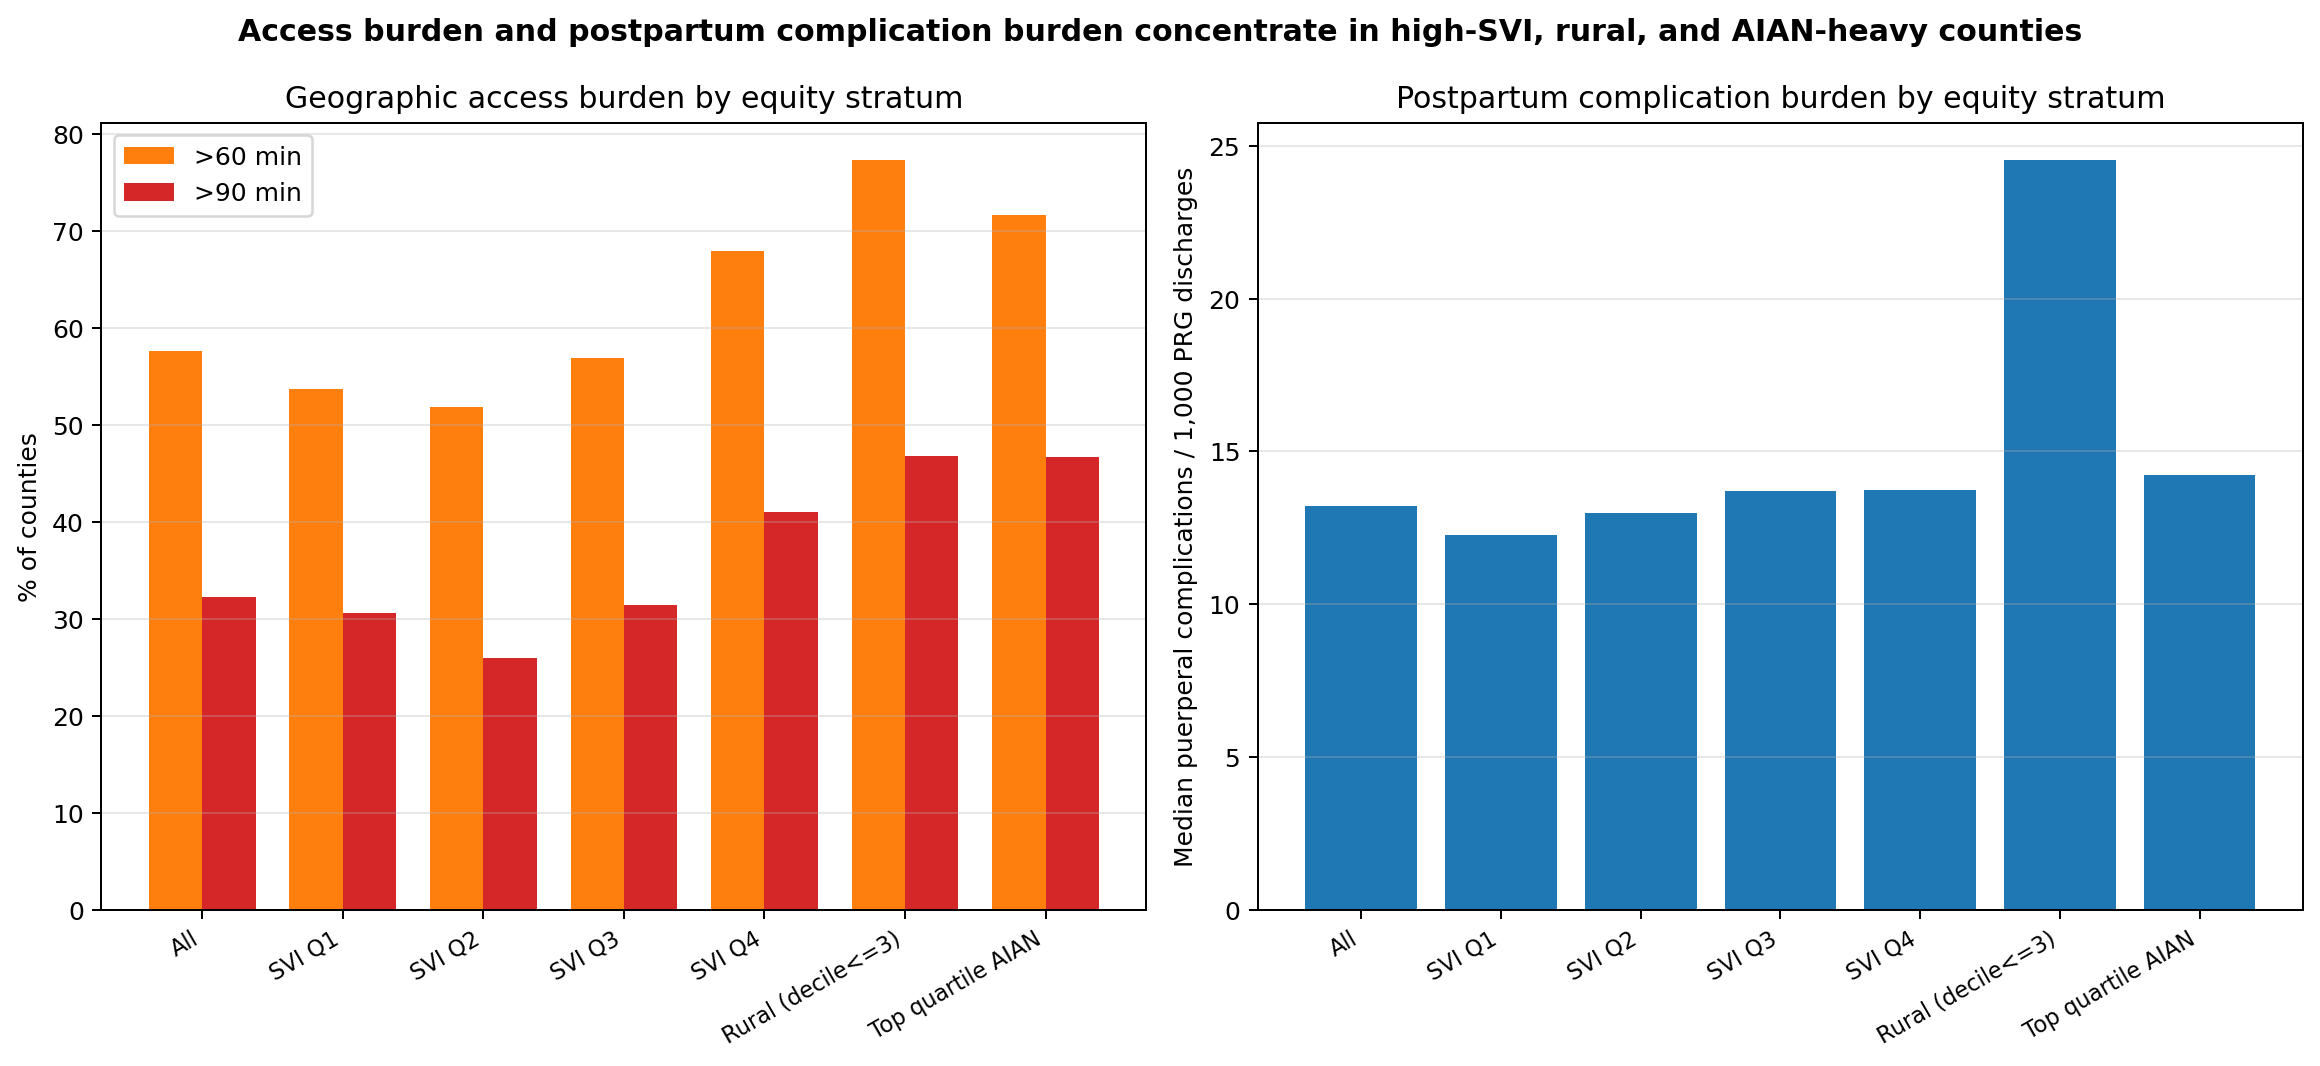

In [13]:
Image(filename=str(C.FIG_DIR / 'fig5_equity_bars.png'))

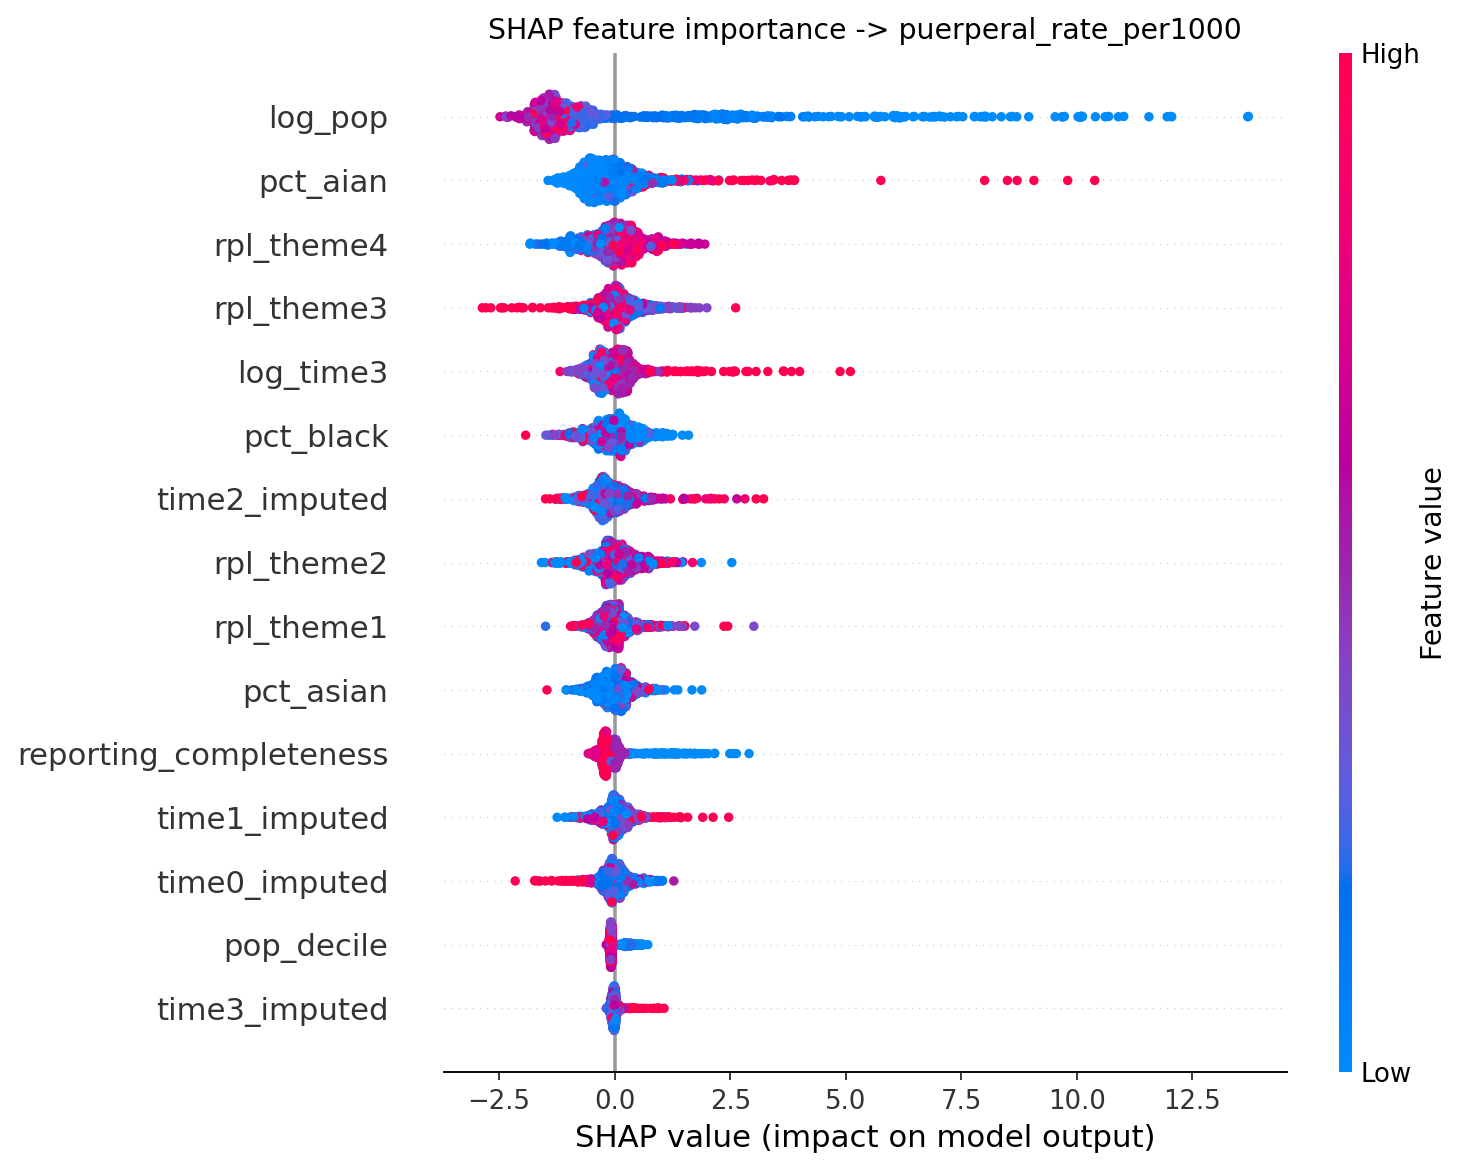

In [14]:
Image(filename=str(C.FIG_DIR / 'fig2_shap_summary_puerperal_rate_per1000.png'))

## 9. The clinical product: MatLevel-CDS demo

`src.cds.recommend(fips, RiskFactors(...))` takes a county FIPS and a structured risk-factor object and returns:
- The ACOG-recommended level of maternal care (rule-based, per Committee Opinion 726)
- Travel time to each level from her county
- The closest reachable level within 30 / 60 min
- A concordance label (`concordant` / `gap` / `severe_gap`)
- Auxiliary county complication-risk scores from the XGBoost models
- An action bundle

Below we run it on three illustrative counties × two patient archetypes.

In [15]:
from dataclasses import asdict

lookup = cohort.set_index('fips')
urban_fips = lookup.sort_values('time3_imputed').index[0]
rural_fips = lookup.sort_values('time3_imputed', ascending=False).index[0]
median_fips = lookup.iloc[(lookup['time3_imputed']
                           - lookup['time3_imputed'].median()).abs().argsort()[:1]].index[0]

picks = [
    ('Urban (closest to Level III)',  urban_fips),
    ('Median-access county',          median_fips),
    ('Rural (farthest from Level III)', rural_fips),
]
print(picks)

[('Urban (closest to Level III)', '26049'), ('Median-access county', '21203'), ('Rural (farthest from Level III)', '02198')]


In [16]:
# A high-risk patient per ACOG: chronic HTN + pregestational DM + prior SMM + class III obesity + AMA
high_risk = RiskFactors(
    chronic_hypertension=True,
    pregestational_diabetes=True,
    prior_severe_maternal_morbidity=True,
    bmi=41.0,
    age_years=38,
)

# A healthy low-risk patient
low_risk = RiskFactors(age_years=27, bmi=26)

for label, fips in picks:
    display(Markdown(f'### {label} — FIPS {fips}'))
    for patient_name, rf in [('High-risk patient', high_risk),
                             ('Low-risk patient', low_risk)]:
        r = recommend(fips, rf)
        display(Markdown(
            f"**{patient_name}** in **{r.county}** (state {r.state_fips})\n"
            f"- Recommended ACOG level: **{r.recommended_level}**\n"
            f"- Travel times (min): {r.travel_times_min}\n"
            f"- Closest within 30 min: `{r.closest_within_30min}` | within 60 min: `{r.closest_within_60min}`\n"
            f"- Concordance: **{r.concordance}** (gap {r.gap_minutes} min)\n"
            f"- SVI quartile: Q{r.svi_quartile} (percentile {r.svi_percentile})\n"
            f"- Maternity desert: {r.maternity_desert}\n"
            f"- Risk factor hits: {r.patient_risk_factors}\n"
            f"- Action bundle:\n" + "\n".join(f'    - {a}' for a in r.action_bundle)
        ))

### Urban (closest to Level III) — FIPS 26049

**High-risk patient** in **Genesee** (state 26)
- Recommended ACOG level: **LEVEL_III**
- Travel times (min): {'LEVEL_I': 1.2, 'LEVEL_II': 1.2, 'LEVEL_III': 1.2, 'LEVEL_IV': 1.2}
- Closest within 30 min: `LEVEL_IV` | within 60 min: `LEVEL_IV`
- Concordance: **concordant** (gap 0.0 min)
- SVI quartile: Q3 (percentile 0.662)
- Maternity desert: False
- Risk factor hits: ['Prior severe maternal morbidity', 'Chronic hypertension', 'Pregestational diabetes', 'Class-III obesity (BMI 41.0)']
- Action bundle:
    - Refer to Maternal-Fetal Medicine at a Level III/IV center for co-management
    - Coordinate delivery-hospital assignment by 28 weeks (earlier if anticipated preterm)
    - Counsel on recognition and immediate presentation for postpartum warning signs (this is the outcome most sensitive to geographic access in our national analysis)

**Low-risk patient** in **Genesee** (state 26)
- Recommended ACOG level: **LEVEL_I**
- Travel times (min): {'LEVEL_I': 1.2, 'LEVEL_II': 1.2, 'LEVEL_III': 1.2, 'LEVEL_IV': 1.2}
- Closest within 30 min: `LEVEL_IV` | within 60 min: `LEVEL_IV`
- Concordance: **concordant** (gap 0.0 min)
- SVI quartile: Q3 (percentile 0.662)
- Maternity desert: False
- Risk factor hits: []
- Action bundle:
    - Routine prenatal care; escalate if risk factors develop
    - Counsel on recognition and immediate presentation for postpartum warning signs (this is the outcome most sensitive to geographic access in our national analysis)

### Median-access county — FIPS 21203

**High-risk patient** in **Rockcastle** (state 21)
- Recommended ACOG level: **LEVEL_III**
- Travel times (min): {'LEVEL_I': 29.3, 'LEVEL_II': 54.4, 'LEVEL_III': 67.4, 'LEVEL_IV': 67.4}
- Closest within 30 min: `LEVEL_I` | within 60 min: `LEVEL_II`
- Concordance: **severe_gap** (gap 37.4 min)
- SVI quartile: Q4 (percentile 0.788)
- Maternity desert: False
- Risk factor hits: ['Prior severe maternal morbidity', 'Chronic hypertension', 'Pregestational diabetes', 'Class-III obesity (BMI 41.0)']
- Action bundle:
    - Refer to Maternal-Fetal Medicine at a Level III/IV center for co-management
    - Coordinate delivery-hospital assignment by 28 weeks (earlier if anticipated preterm)
    - High social vulnerability quartile: engage social work early for transportation, housing, and insurance barriers
    - Counsel on recognition and immediate presentation for postpartum warning signs (this is the outcome most sensitive to geographic access in our national analysis)

**Low-risk patient** in **Rockcastle** (state 21)
- Recommended ACOG level: **LEVEL_I**
- Travel times (min): {'LEVEL_I': 29.3, 'LEVEL_II': 54.4, 'LEVEL_III': 67.4, 'LEVEL_IV': 67.4}
- Closest within 30 min: `LEVEL_I` | within 60 min: `LEVEL_II`
- Concordance: **concordant** (gap 0.0 min)
- SVI quartile: Q4 (percentile 0.788)
- Maternity desert: False
- Risk factor hits: []
- Action bundle:
    - Routine prenatal care; escalate if risk factors develop
    - High social vulnerability quartile: engage social work early for transportation, housing, and insurance barriers
    - Counsel on recognition and immediate presentation for postpartum warning signs (this is the outcome most sensitive to geographic access in our national analysis)

### Rural (farthest from Level III) — FIPS 02198

**High-risk patient** in **Prince of Wales-Hyder Census Area** (state 02)
- Recommended ACOG level: **LEVEL_III**
- Travel times (min): {'LEVEL_I': 598.7, 'LEVEL_II': 598.7, 'LEVEL_III': 3658.6, 'LEVEL_IV': 3658.6}
- Closest within 30 min: `None` | within 60 min: `None`
- Concordance: **severe_gap** (gap 3628.6 min)
- SVI quartile: Q3 (percentile 0.766)
- Maternity desert: True
- Risk factor hits: ['Prior severe maternal morbidity', 'Chronic hypertension', 'Pregestational diabetes', 'Class-III obesity (BMI 41.0)']
- Action bundle:
    - Refer to Maternal-Fetal Medicine at a Level III/IV center for co-management
    - Coordinate delivery-hospital assignment by 28 weeks (earlier if anticipated preterm)
    - Patient is ~3629 min from the nearest Level III facility: arrange antepartum transfer plan, lodging near delivery hospital, or telehealth MFM co-management
    - County meets 'maternity care desert' criteria: counsel patient on early transfer of care and emergency transport pathway
    - Counsel on recognition and immediate presentation for postpartum warning signs (this is the outcome most sensitive to geographic access in our national analysis)

**Low-risk patient** in **Prince of Wales-Hyder Census Area** (state 02)
- Recommended ACOG level: **LEVEL_I**
- Travel times (min): {'LEVEL_I': 598.7, 'LEVEL_II': 598.7, 'LEVEL_III': 3658.6, 'LEVEL_IV': 3658.6}
- Closest within 30 min: `None` | within 60 min: `None`
- Concordance: **severe_gap** (gap 568.7 min)
- SVI quartile: Q3 (percentile 0.766)
- Maternity desert: True
- Risk factor hits: []
- Action bundle:
    - Routine prenatal care; escalate if risk factors develop
    - County meets 'maternity care desert' criteria: counsel patient on early transfer of care and emergency transport pathway
    - Counsel on recognition and immediate presentation for postpartum warning signs (this is the outcome most sensitive to geographic access in our national analysis)

## 10. Counterfactual exploration — what if we added a Level-III facility?

A simple simulation: pretend a new Level-III hospital opens at the centroid of a chosen county, and recompute every county's `time3` as `min(original_time3, straight-line estimate to the new facility)`. We use a rough 60 km/h conversion from straight-line Haversine distance as a quick approximation (the original ArcGIS OD matrix is not reproducible here without proprietary road data, so this is illustrative only).

In [17]:
# Build a lookup of county (fips -> approximate centroid lat/lon) using a
# public census gazetteer if available. For now, we cannot reproduce the
# ArcGIS OD matrix, but we can still rank counties by how much a new Level-III
# at an urban-proximate county would help the farthest-underserved counties.
# This cell is illustrative.

farthest = cohort.nlargest(15, 'time3_imputed')[['fips','county','state_fips','time3_imputed']]
farthest

,fips,county,state_fips,time3_imputed
15,02198,Prince of Wales-Hyder Census Area,02,3658.573730
14,02195,Petersburg Census Area,02,2849.812744
16,02220,Sitka City and Borough,02,1982.669800
0,02016,Aleutians West Census Area,02,1283.637085
2,02050,Bethel Census Area,02,1283.637085
3,02070,Dillingham Census Area,02,1283.637085
5,02110,Juneau City and Borough,02,1283.637085
6,02122,Kenai Peninsula Borough,02,1283.637085
7,02130,Ketchikan Gateway Borough,02,1283.637085
8,02150,Kodiak Island Borough,02,1283.637085


## 11. Conclusions

- **Access gaps are massive and quantifiable.** 87% of counties sit more than 30 min from the nearest ACOG Level-III facility; 32% are more than 90 min away. One-third meet a composite 'maternity desert' definition.
- **Naive discharge-based regression fails.** The Negative Binomial GLM returns null associations because HCUP counts discharges at the hospital location, not the patient's residence. Regional referral centers absorb high-risk transfers and inflate urban coded rates.
- **DoubleML reveals the sign-reversal.** Antepartum/intrapartum outcomes show apparent protection from distance (referral capture bias); **puerperal (postpartum) complications show the genuine residential access signal, strengthened in the rural subsample**.
- **Burden concentrates.** Rural counties carry ~2× the postpartum complication burden of non-rural counties and are twice as likely to be >90 min from Level III care. SVI-Q4 and top-quartile-AIAN counties show the same pattern.
- **Clinical product.** MatLevel-CDS takes a county FIPS + structured risk factors at the first prenatal visit and returns an ACOG-recommended level of care, travel times to each level, a concordance label, and an action bundle. The ACOG rule engine is deterministic (Committee Opinion 726); the ML provides auxiliary county risk scores and the causal evidence base.

### Next steps
- Link an outcome-based denominator (CDC WONDER natality or HRSA Maternity Care Target Areas) to confirm the puerperal finding against a residence-based reference.
- Build the county-centroid lat/lon table to enable the counterfactual 'move the hospital' simulation.
- Wire the CDS scoring function behind a FastAPI `/recommend` endpoint deployed to Render, with the Vercel frontend consuming `/counties`, `/access/{fips}`, and `/recommend`.